# 3 · 网络 meta 分析（NMA）

!!! note "示例数据"
    这里用一个小型的**教学用网络**（4 个干预、6 个直接比较），目的是演示 API，
    不是真实临床结论。把 `TE/seTE` 换成你自己的数据即可。

NMA 要回答的是：**A、B、C、D 两两之间谁更好**，即使某些对子从来没有被直接比较过。


In [1]:
import numpy as np

import pimeta as ma

# 6 个直接比较。比值类指标要先取对数，再作为 TE 传进去。
TE = [0.30, -0.20, 0.50, 0.10, -0.15, 0.25]
seTE = [0.12, 0.15, 0.18, 0.14, 0.11, 0.13]
treat1 = ["A", "B", "A", "C", "B", "C"]
treat2 = ["B", "A", "C", "A", "C", "B"]
studlab = ["S1", "S2", "S3", "S4", "S5", "S6"]

print(f"{len(TE)} 个比较，涉及 {len(set(treat1) | set(treat2))} 个干预")

6 个比较，涉及 3 个干预


## 拟合网络

`netmeta()` 默认同时给 frequentist 的固定效应与随机效应结果。

In [2]:
nm = ma.netmeta(TE, seTE, treat1, treat2, studlab, sm="RR")

print("干预       :", list(nm.trts))
print("比较数 m   :", nm.m)
print(f"tau^2      : {nm.tau2:.5f}")
print(f"总 Q       : {nm.Q:.4f} (df={nm.df_Q:g}, p={nm.pval_Q:.4f})")
print(f"  └ 异质性 : {nm.Q_heterogeneity:.4f}")
print(f"  └ 不一致 : {nm.Q_inconsistency:.4f}")

干预       : ['A', 'B', 'C']
比较数 m   : 6
tau^2      : 0.01680
总 Q       : 7.6544 (df=4, p=0.1051)
  └ 异质性 : 7.5389
  └ 不一致 : 0.1155


## 相对效应是一个 n×n 矩阵

和 R 的 `$TE.random` 一样，矩阵第 `[i, j]` 元就是干预 `j` 相对干预 `i` 的效应（对角线上是 `nan`）。

In [3]:
import pandas as pd

n = len(nm.trts)
mat = pd.DataFrame(np.asarray(nm.TE_random, dtype=float),
                   index=[f"vs {t}" for t in nm.trts], columns=nm.trts)
print(mat.round(4).to_string())

           A       B       C
vs A     NaN  0.2866  0.1180
vs B -0.2866     NaN -0.1686
vs C -0.1180  0.1686     NaN


## 排名：P-score

In [4]:
rk = ma.netrank(nm)

score = pd.Series(np.asarray(rk.pscore_random, dtype=float),
                  index=nm.trts).sort_values(ascending=False)
print("P-score（1 = 最好，0 = 最差）")
print(score.round(4).to_string())

P-score（1 = 最好，0 = 最差）
B    0.9707
C    0.4531
A    0.0763


## 联赛表（league table）

`netleague()` 返回的是 R 里那种**已经排好版的字符串矩阵**：对角线是干预名，
**下三角是网络估计**，**上三角是直接比较**（metafor/netmeta 的约定）。

In [5]:
lg = ma.netleague(nm)
print("干预顺序:", list(lg.trts))
print()
print(pd.DataFrame(lg.random, index=nm.trts, columns=nm.trts).to_string())
print()
print(lg.details)

干预顺序: ['A', 'B', 'C']

                           A                           B                          C
A                          A    0.2557 [-0.0027; 0.5142]   0.1551 [-0.1284; 0.4386]
B  0.2866 [ 0.0739;  0.4993]                           B  -0.1962 [-0.4406; 0.0483]
C  0.1180 [-0.1037;  0.3397]  -0.1686 [-0.3747;  0.0376]                          C


Lower triangle: results from network meta-analysis (column vs row)
Upper triangle: results from direct comparisons (row vs column)



## 一致性：直接证据 vs 间接证据

每个比较拆成直接部分和间接部分，两者不一致说明网络内部有矛盾。

In [6]:
sp = ma.netsplit(nm)
print(pd.DataFrame({
    "比较": sp.comparison,
    "k": sp.k,
    "直接": np.round(sp.direct_random["TE"], 4),
    "间接": np.round(sp.indirect_random["TE"], 4),
}).to_string(index=False))

 比较  k      直接      间接
A:B  2  0.2557  0.3513
A:C  2  0.1551  0.0596
B:C  2 -0.1962 -0.1006


## 排名图：P-score

（`netheat()` 需要 design-by-treatment 分解，`netmeta()` 目前还没算这个矩阵，
所以这里换成更直接的排名图；不一致性请看上面的 `netsplit()`。）

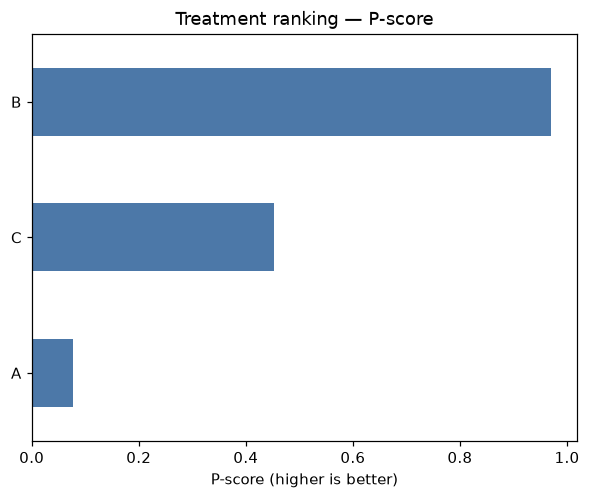

In [7]:
ax = score.sort_values().plot.barh(color="#4c78a8")
ax.set_xlabel("P-score (higher is better)")
_ = ax.set_title("Treatment ranking — P-score")

## 小结

| 想知道 | 用 |
|---|---|
| 两两相对效应 | `nm.TE_random[i, j]`（n×n 矩阵） |
| 谁最好 | `ma.netrank(nm).pscore_random` |
| 贴论文的联赛表 | `ma.netleague(nm).random` |
| 直接/间接是否一致 | `ma.netsplit(nm)` |
| 不一致性来源 | `ma.netheat(nm)` |

原始 2×2 数据可以用 `ma.netmetabin(event1, n1, event2, n2, treat1, treat2)` 直接喂，
它会在内部做 Mantel-Haenszel / 逆方差等合并。